# Exploring the voxel idea with a small 2D precursor

**Status: Under investigation.** This notebook explores a proposed method; it does not reproduce an MRI dataset or establish a tissue law. All numbers and loads are synthetic. Numerical assertions are not Lean proofs.

The experiments deliberately answer different questions:

1. Can 2D and 3D grids of axial connections resist the deformations we expect?
2. Can a collection of measurements distinguish eight material coefficients?

The lattice is a discrete connection model. The eight-coefficient example is a separate planar orthotropic Kelvin–Voigt continuum law. We do not claim they are equivalent, and its eight coefficients are **not** four independently fitted pixel sides.

Read the [model chapter](../docs/models/VoxelMechanics.md), [literature and decision guide](../docs/research/003-voxel-method-literature.md), and [source map](../docs/SOURCE_MAP.md). The single implementation used below is [experiments/voxel_method.py](../experiments/voxel_method.py). Running this notebook regenerates the [figure](../docs/assets/voxel-method.png) and [numerical report](../docs/research/voxel-method-results.json).


All synthetic numerical assertions passed.
{
  "python": "3.13.5",
  "numpy": "2.5.4",
  "matplotlib": "3.11.2"
}


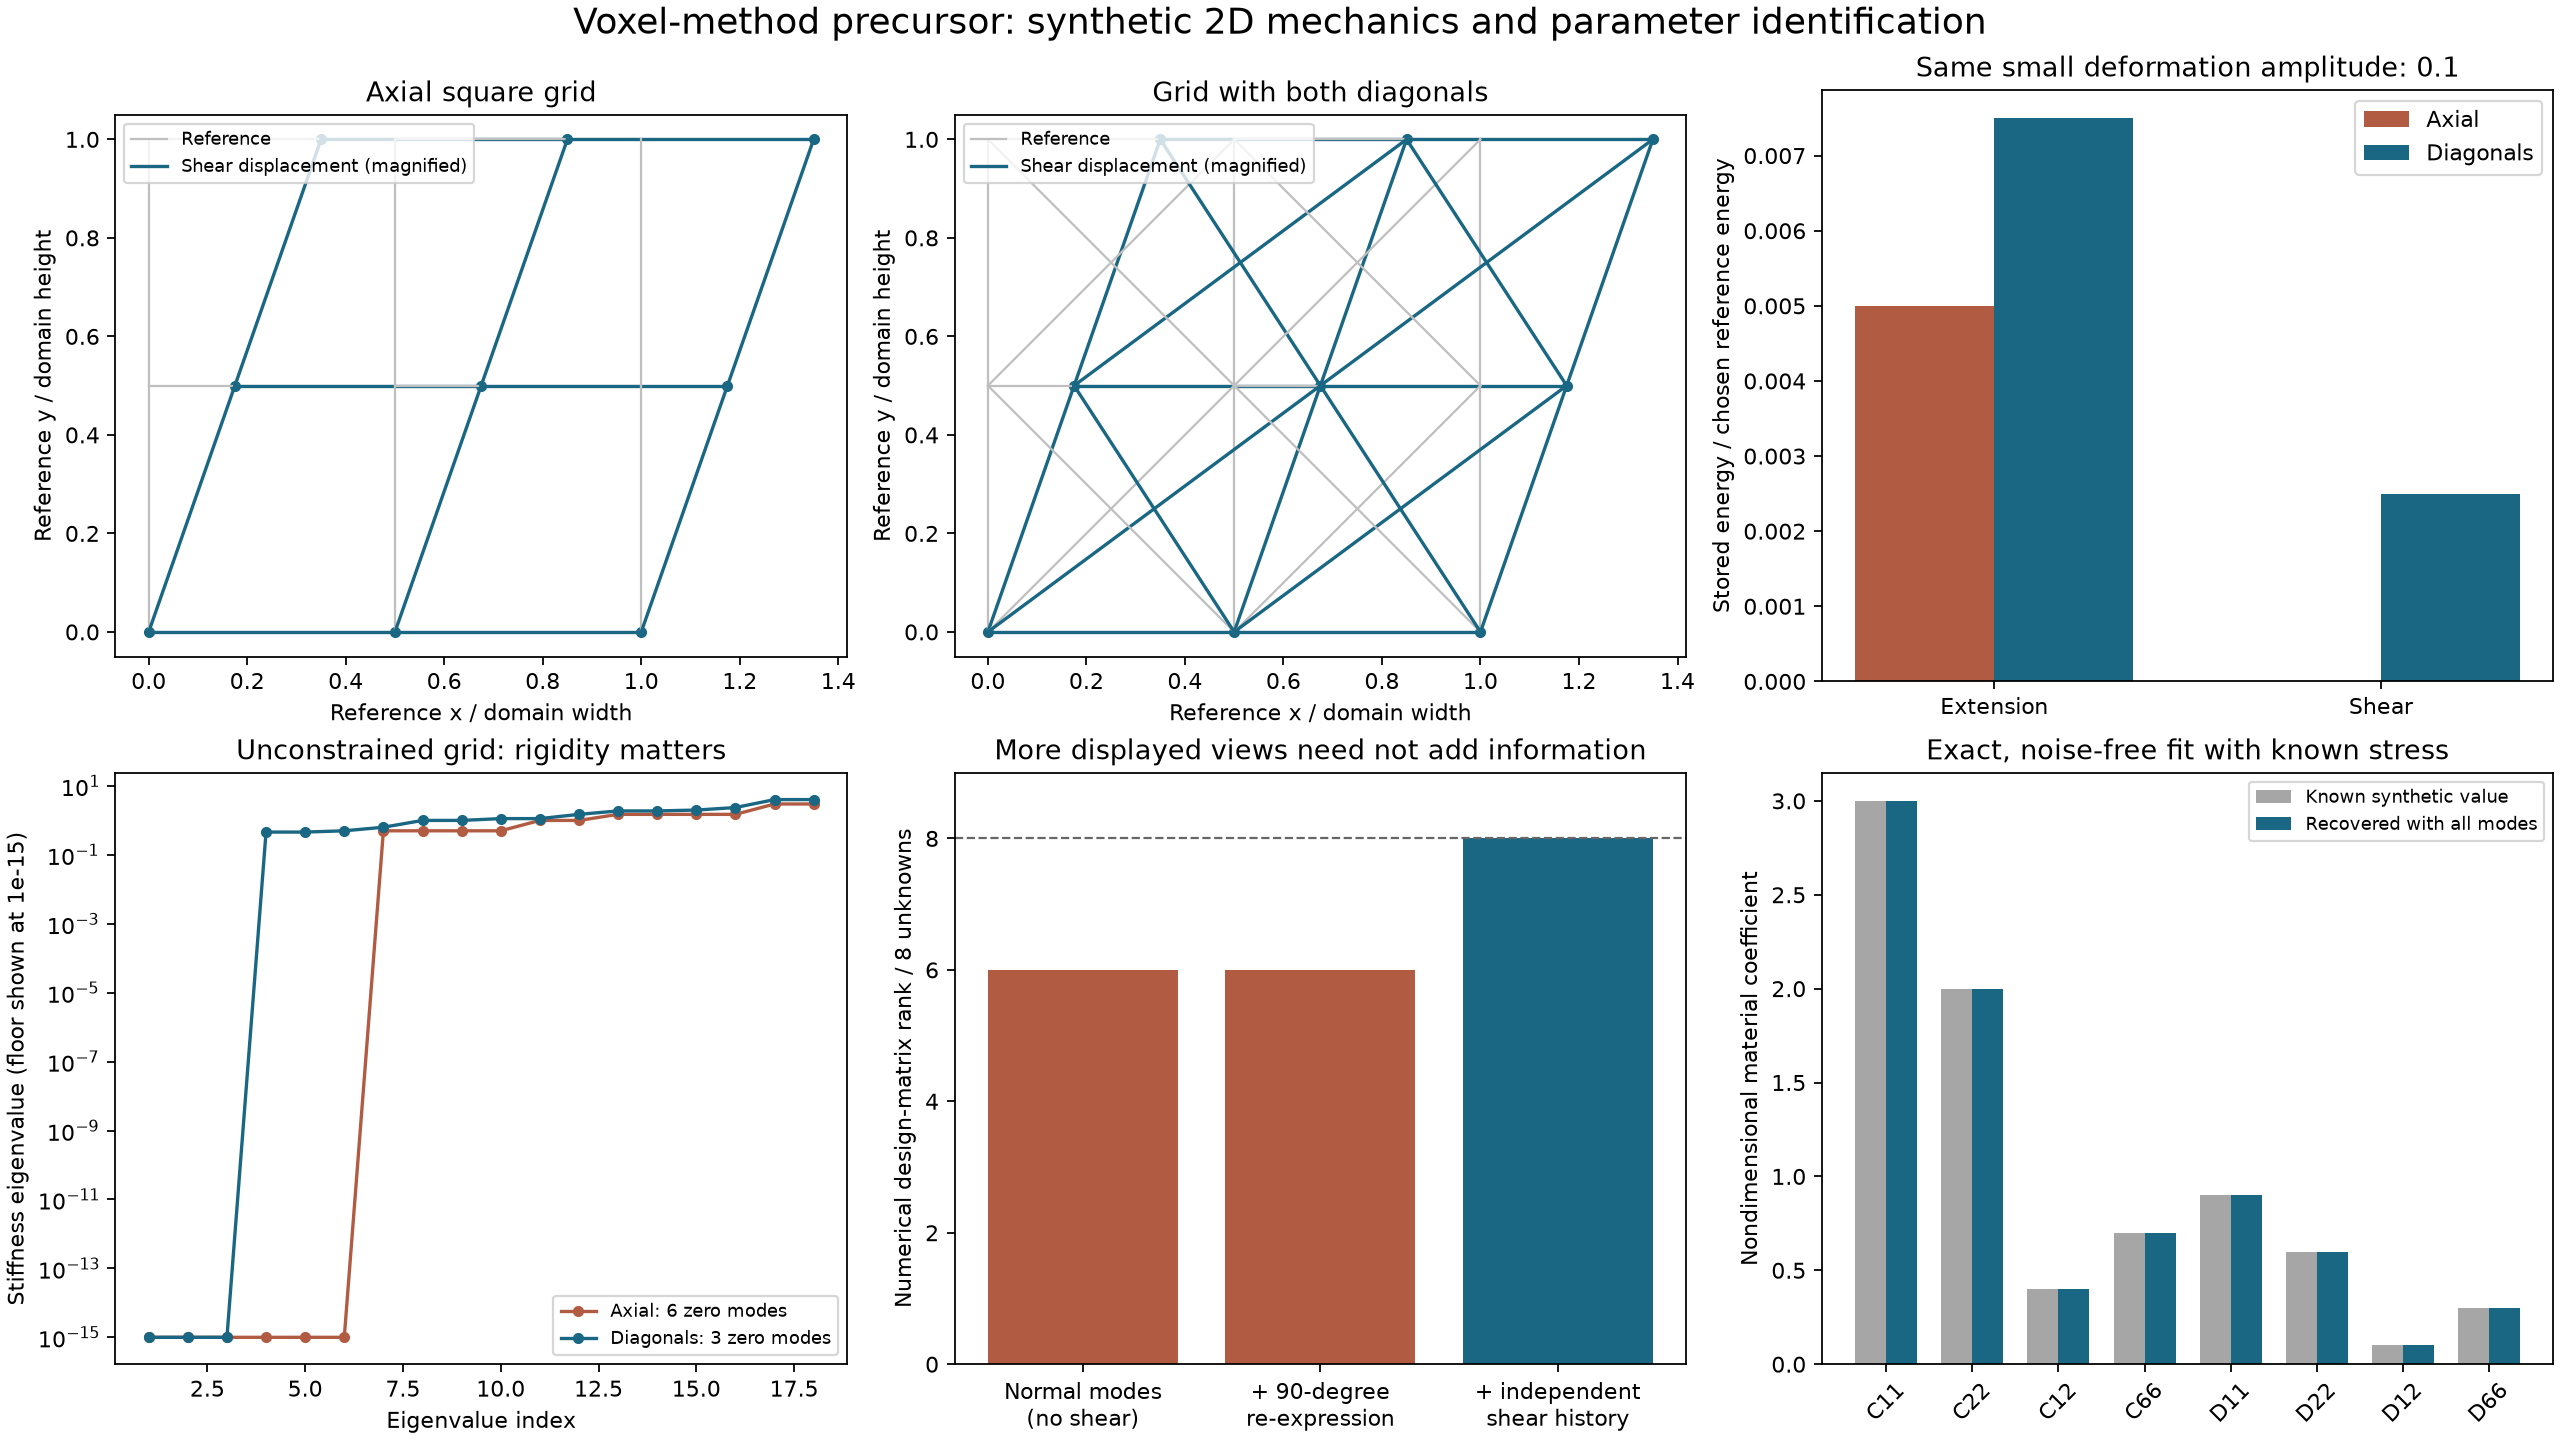

In [1]:
from pathlib import Path
import importlib.util
import json
import matplotlib.pyplot as plt
from IPython.display import Image, display

repo = Path.cwd().resolve()
if not (repo / "experiments/voxel_method.py").is_file():
    repo = repo.parent
spec = importlib.util.spec_from_file_location("voxel_method", repo / "experiments/voxel_method.py")
voxel = importlib.util.module_from_spec(spec)
spec.loader.exec_module(voxel)
report, fig = voxel.run_exploration()
print("All synthetic numerical assertions passed.")
print(json.dumps(report["environment"], indent=2))
display(Image(filename=str(repo / "docs/assets/voxel-method.png"), width=1200))
plt.close(fig)


## 1. Geometry, compatibility, and the shear test

Each graph node has two displacement components. For a unique link joining reference points $X_i$ and $X_j$, use

$$n_{ij}=\frac{X_j-X_i}{\lVert X_j-X_i\rVert},\qquad q_{ij}=n_{ij}\cdot(u_j-u_i).$$

The matrix $B$ collects these rules into $q=Bu$. Positive $q$ means extension. Link forces are applied with equal and opposite signs, giving internal nodal force $-B^T F$.

For the displacement $u(x,y)=(\gamma y,0)$, horizontal and vertical axial links have zero first-order extension. Therefore a square grid of such links cannot resist infinitesimal shear. This is consistent with [Mao, Xu and Lubensky (2010)](https://arxiv.org/abs/0909.2616). Adding both diagonals to each cell removes that particular mechanism in this small patch; it does not establish rigidity for every segmented geometry or match an arbitrary tissue tensor.

The stiffness matrix is $K=B^T\operatorname{diag}(k)B$. Its zero modes include free translations and an infinitesimal rotation. We compare the free matrix with a matrix constrained by fixing lower-left displacement in both directions and lower-right vertical displacement. The remaining zero modes show whether deformations other than those three rigid motions remain.

The drawing magnifies the shear to make it visible. The laws and energy checks use the explicitly stated small-deformation model; invariance under finite rotations is not established.


In [2]:
for key in ["four_neighbor", "with_diagonals"]:
    item = report["graph"][key]
    print(key)
    print("  nodes / links:", item["nodes"], "/", item["links"])
    print("  free / constrained zero modes:", item["free_stiffness"]["nullity"],
          "/", item["constrained_stiffness"]["nullity"])
    print("  normalized extension / shear energy:", item["energy"])


four_neighbor
  nodes / links: 9 / 12
  free / constrained zero modes: 6 / 3
  normalized extension / shear energy: {'extension': 0.005000000000000001, 'shear': 0.0}
with_diagonals
  nodes / links: 9 / 20
  free / constrained zero modes: 3 / 0
  normalized extension / shear energy: {'extension': 0.007500000000000002, 'shear': 0.0025}


## A small 3D voxel-connectivity check

A separate $3\times3\times3$ node patch compares six-neighbor axial connections with an enriched graph containing all local face and body diagonals. Every connection has positive unit stiffness. We check translation, an infinitesimal rigid rotation, and the simple shear field $u(x,y,z)=(0.1y,0,0)$.

The free graph should contain six rigid-body modes: three translations and three infinitesimal rotations. Additional zero modes indicate missing resistance. To remove the six rigid freedoms, we constrain the origin in all directions, the positive-x corner in y and z, and the positive-y corner in z.

This is a **numerical topology check**, not a 3D tissue constitutive model. The weights are not calibrated material parameters; no 3D Maxwell evolution, MRI processing, incompressibility, or finite-strain law is supplied. The Lean declarations in this contribution remain planar.


In [3]:
for key in ["six_neighbor", "face_and_body_diagonals"]:
    item = report["voxel_topology_3d"][key]
    print(key)
    print("  nodes / links:", item["nodes"], "/", item["links"])
    print("  free / constrained zero modes:", item["free_stiffness"]["nullity"],
          "/", item["constrained_stiffness"]["nullity"])
    print("  normalized simple shear energy:", item["simple_shear_energy"])


six_neighbor
  nodes / links: 27 / 54
  free / constrained zero modes: 27 / 21
  normalized simple shear energy: 0.0
face_and_body_diagonals
  nodes / links: 27 / 158
  free / constrained zero modes: 6 / 0
  normalized simple shear energy: 0.028333333333333342


## 2. Passivity and a limited refinement check

For a Kelvin–Voigt branch in parallel with a Maxwell branch, use extension $q$, Maxwell force $z$, and

$$F=k_0q+c_0\dot q+z,\qquad \dot z=k_1(\dot q-z/c_1).$$

With $k_0,c_0\geq0$ and $k_1,c_1>0$, stored energy and dissipation rate are

$$W=\tfrac12 k_0q^2+\frac{z^2}{2k_1},\qquad D=c_0\dot q^2+z^2/c_1\geq0.$$

The pointwise identity is $F\dot q=\dot W+D$. Summing it and using nodal force assembly yields the expected global power balance when supplied rates and forces are consistent. The script checks these algebraic identities numerically. It does not integrate the equations or prove a work inequality for trajectories. The scalar branch-law derivations are documented in [Chapter 4](../docs/models/PassiveViscoelasticity.md); no published fitted coefficients are copied here.

The toy lattice assigns half weight to outer horizontal/vertical links and weight $1/2$ to each diagonal. For the chosen uniform affine extension and shear fields, these weights keep total energy constant as the grid is refined. This is an **affine patch consistency check**, not a proof of continuum convergence or a uniquely determined conversion from tissue modulus to diagonal stiffness. All graph values use arbitrary consistent reference units.


In [4]:
for key in ["four_neighbor", "with_diagonals"]:
    item = report["graph"][key]
    print(key, {
        "edge_power_residual": item["max_edge_power_residual"],
        "paired_force_sum_norm": item["paired_force_sum_norm"],
        "virtual_work_residual": item["virtual_work_residual"],
        "dynamic_power_residual": item["dynamic_power_residual"],
    })
print("Affine patch energies:")
print(json.dumps(report["graph"]["affine_patch_refinement"], indent=2))


four_neighbor {'edge_power_residual': 1.734723475976807e-18, 'paired_force_sum_norm': 5.551115123125783e-17, 'virtual_work_residual': 0.0, 'dynamic_power_residual': 0.0}
with_diagonals {'edge_power_residual': 3.469446951953614e-18, 'paired_force_sum_norm': 2.7755575615628914e-17, 'virtual_work_residual': 2.7755575615628914e-17, 'dynamic_power_residual': -2.7755575615628914e-17}
Affine patch energies:
[
  {
    "nodes_per_axis": 2,
    "extension_energy": 0.0075000000000000015,
    "shear_energy": 0.0025
  },
  {
    "nodes_per_axis": 3,
    "extension_energy": 0.007500000000000002,
    "shear_energy": 0.0025
  },
  {
    "nodes_per_axis": 5,
    "extension_energy": 0.0075000000000000015,
    "shear_energy": 0.002500000000000001
  },
  {
    "nodes_per_axis": 9,
    "extension_energy": 0.007500000000000001,
    "shear_energy": 0.0024999999999999996
  }
]


## 3. An explicit eight-parameter identification example

Assume known material axes and the engineering-shear convention

$$e=(\varepsilon_{xx},\varepsilon_{yy},\gamma_{xy}),\quad\gamma_{xy}=2\varepsilon_{xy},\qquad
s=(\sigma_{xx},\sigma_{yy},\tau_{xy}).$$

Choose the illustrative planar orthotropic law $s=Ce+D\dot e$, with

$$C=\begin{pmatrix}C_{11}&C_{12}&0\\C_{12}&C_{22}&0\\0&0&C_{66}\end{pmatrix},\qquad
D=\begin{pmatrix}D_{11}&D_{12}&0\\D_{12}&D_{22}&0\\0&0&D_{66}\end{pmatrix}.$$

There are four elastic and four viscous coefficients. Positive definite $C$ gives positive stored strain energy; positive semidefinite $D$ gives nonnegative viscous dissipation. Both chosen matrices are positive definite. This is a project-selected teaching model, not an experimentally identified myocardial law. A large-deformation, nearly incompressible, fiber-oriented tissue model needs additional decisions.

We prescribe **known synthetic stress and strain/rate data**. Actual MRI supplies neither this complete stress history nor a solved inverse problem. Normalization uses strain reference $0.01$, stress reference $100$ Pa, and time reference $1$ s. Thus elastic coefficients are reported relative to $10000$ Pa and viscous coefficients relative to $10000$ Pa·s. The design matrix uses these dimensionless variables before SVD diagnostics.

The fit is $A\theta=y$, where $\theta=(C_{11},C_{22},C_{12},C_{66},D_{11},D_{22},D_{12},D_{66})$. Without shear or shear rate, the $C_{66}$ and $D_{66}$ columns are zero. Additional displayed views of those same data cannot fill those columns.


In [5]:
inverse = report["inverse"]
for key in ["no_shear", "same_no_shear_data_plus_90_degree_reexpression",
            "independent_normal_shear_and_rate_histories"]:
    diagnostic = inverse[key]
    print(key, {
        "equations": diagnostic["rows"], "unknowns": diagnostic["columns"],
        "rank": diagnostic["rank"],
        "condition_number_if_full_rank": diagnostic["full_column_rank_condition_number"],
    })
print("Parameter order:", inverse["parameter_order"])
print("True:", inverse["true_coefficients"])
print("Recovered:", inverse["recovered_coefficients"])
print("Maximum absolute recovery error:", inverse["maximum_recovery_error"])
print("C eigenvalues:", inverse["elastic_matrix_eigenvalues"])
print("D eigenvalues:", inverse["viscous_matrix_eigenvalues"])


no_shear {'equations': 363, 'unknowns': 8, 'rank': 6, 'condition_number_if_full_rank': None}
same_no_shear_data_plus_90_degree_reexpression {'equations': 726, 'unknowns': 8, 'rank': 6, 'condition_number_if_full_rank': None}
independent_normal_shear_and_rate_histories {'equations': 363, 'unknowns': 8, 'rank': 8, 'condition_number_if_full_rank': 24.684066751448224}
Parameter order: ['C11', 'C22', 'C12', 'C66', 'D11', 'D22', 'D12', 'D66']
True: [3.0, 2.0, 0.4, 0.7, 0.9, 0.6, 0.1, 0.3]
Recovered: [3.000000000000001, 1.9999999999999993, 0.4000000000000026, 0.6999999999999993, 0.8999999999999997, 0.6000000000000065, 0.09999999999999759, 0.30000000000000004]
Maximum absolute recovery error: 6.5503158452884236e-15
C eigenvalues: [0.7, 1.859687576256715, 3.1403124237432847]
D eigenvalues: [0.3, 0.5697224362268004, 0.9302775637731995]


## 4. What does a 90-degree view add?

For a 90-degree coordinate change in this planar example,

$$s'=S s,\quad e'=S e,\qquad S=\begin{pmatrix}0&1&0\\1&0&0\\0&0&-1\end{pmatrix}.$$

The script stacks $SA\theta=Sy$ with $A\theta=y$. Both use the **same original material coefficients**; the new rows are combinations of the old rows. Rank stays six in the no-shear case. As a separate consistency check, transforming material matrices as $C'=SCS^T$, $D'=SDS^T$ gives the transformed stresses, and mechanical power is unchanged.

A genuinely additional measurement can help when it observes a component missing before. The separate geometry illustration below compares an idealized displacement projector that observes $(u_x,u_y)$ with one that observes $(u_y,u_z)$. Together they can observe all three displacement components. Merely rotating the displayed $(u_x,u_y)$ pair cannot recover $u_z$. These are idealized observation operators: an actual acquisition must supply the additional encoded information. The rank-three displacement reconstruction does **not** imply rank-eight material identification.


In [6]:
print(json.dumps(inverse["observation_geometry"], indent=2))
print("Single KV history with qdot proportional to q: rank =",
      inverse["single_KV_collinear_history_rank"])
print("Indistinguishable positive (k,c) pairs:",
      inverse["single_KV_indistinguishable_pairs"])


{
  "single_xy_projection_rank": 2,
  "same_projection_reexpressed_rank": 2,
  "independently_observed_xy_and_yz_rank": 3,
  "scope": "Idealized displacement projectors; an additional encoded component is assumed, not supplied by rotating an image."
}
Single KV history with qdot proportional to q: rank = 1
Indistinguishable positive (k,c) pairs: [[2.0, 3.0], [3.0, 2.0]]


## 5. Remaining questions for later review

- Which MRI acquisition will supply geometry, displacement components, and timing?
- What loading information is available? Scaling both material coefficients and unknown applied stress can preserve the same deformation.
- Is the target a discrete mechanical network, a tensor material on image cells, or a reduced model derived from 3D mechanics?
- Can the assumed reference state and residual activation be justified?
- What changes when data contain noise, strain rates must be estimated, or loading is uncertain?
- Does a proposed parameterization have sufficient independent measurements after masking and boundary conditions?
- What additional constitutive assumptions would connect slow stretching with high-frequency MR elastography?

The next experiment should add uncertainty and a forward boundary-value problem before attempting patient-specific parameter recovery. There is no MRI import, tissue segmentation, 3D constitutive voxel model, active contraction, arbitrary-mask rigidity guarantee, or clinical claim in this notebook. The 3D contribution is limited to the connectivity check above. See the JSON report for exact numerical tolerances and limitations.
